In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Initial experiment seed
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Request deterministic TensorFlow operations where supported
tf.config.experimental.enable_op_determinism()

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Initial seed:", SEED)

TensorFlow version: 2.21.0
NumPy version: 2.1.3
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Initial seed: 42


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

DATA_DIR = Path("/content/drive/MyDrive/DL_Assignment/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = DATA_DIR / "cifar10_prepared.npz"

# Download and prepare only if the saved file doesn't exist
if not DATA_FILE.exists():

    (x_train_full, y_train_full), (clean_test, y_clean_test) = (
        tf.keras.datasets.cifar10.load_data()
    )

    y_train_full = y_train_full.flatten()
    y_clean_test = y_clean_test.flatten()

    rng = np.random.default_rng(SEED)
    selected_indices = []

    for class_id in range(10):
        class_indices = np.where(y_train_full == class_id)[0]
        selected_indices.extend(
            rng.choice(class_indices, size=50, replace=False)
        )

    selected_indices = np.array(selected_indices)
    selected_indices = rng.permutation(selected_indices)

    train_small = x_train_full[selected_indices]
    y_small = y_train_full[selected_indices]

    train_idx, val_idx = train_test_split(
        np.arange(500),
        test_size=100,
        random_state=SEED,
        stratify=y_small
    )

    np.savez_compressed(
        DATA_FILE,
        train_small=train_small,
        y_small=y_small,
        train_idx=train_idx,
        val_idx=val_idx,
        clean_test=clean_test,
        y_clean_test=y_clean_test
    )

    print("Dataset prepared and saved to Google Drive.")

else:
    print("Saved dataset already exists. No download needed.")

print("Dataset file:", DATA_FILE)

Mounted at /content/drive
Saved dataset already exists. No download needed.
Dataset file: /content/drive/MyDrive/DL_Assignment/data/cifar10_prepared.npz


In [11]:
# Load the saved dataset
data = np.load(DATA_FILE)

# Access individual arrays
train_small = data["train_small"]
y_small = data["y_small"]
train_idx = data["train_idx"]
val_idx = data["val_idx"]
clean_test = data["clean_test"]
y_clean_test = data["y_clean_test"]

print("Training images:", train_small.shape)
print("Training labels:", y_small.shape)
print("Training indices:", train_idx.shape)
print("Validation indices:", val_idx.shape)
print("Clean test images:", clean_test.shape)
print("Clean test labels:", y_clean_test.shape)
x_train = train_small[train_idx]
y_train = y_small[train_idx]

x_val = train_small[val_idx]
y_val = y_small[val_idx]


Training images: (500, 32, 32, 3)
Training labels: (500,)
Training indices: (400,)
Validation indices: (100,)
Clean test images: (10000, 32, 32, 3)
Clean test labels: (10000,)


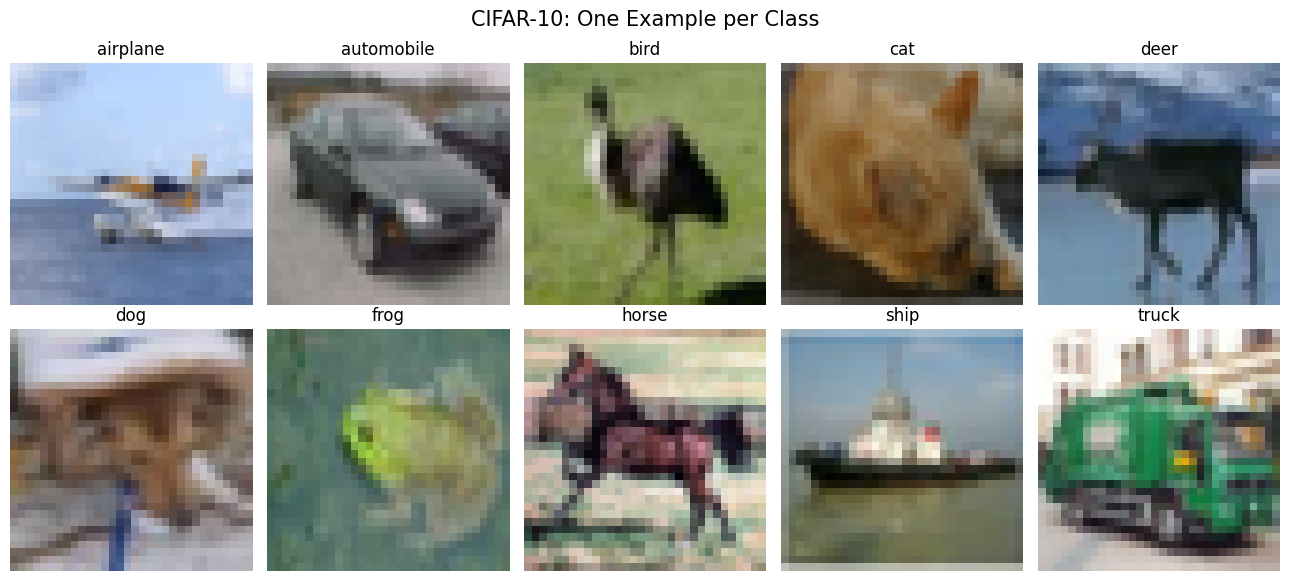

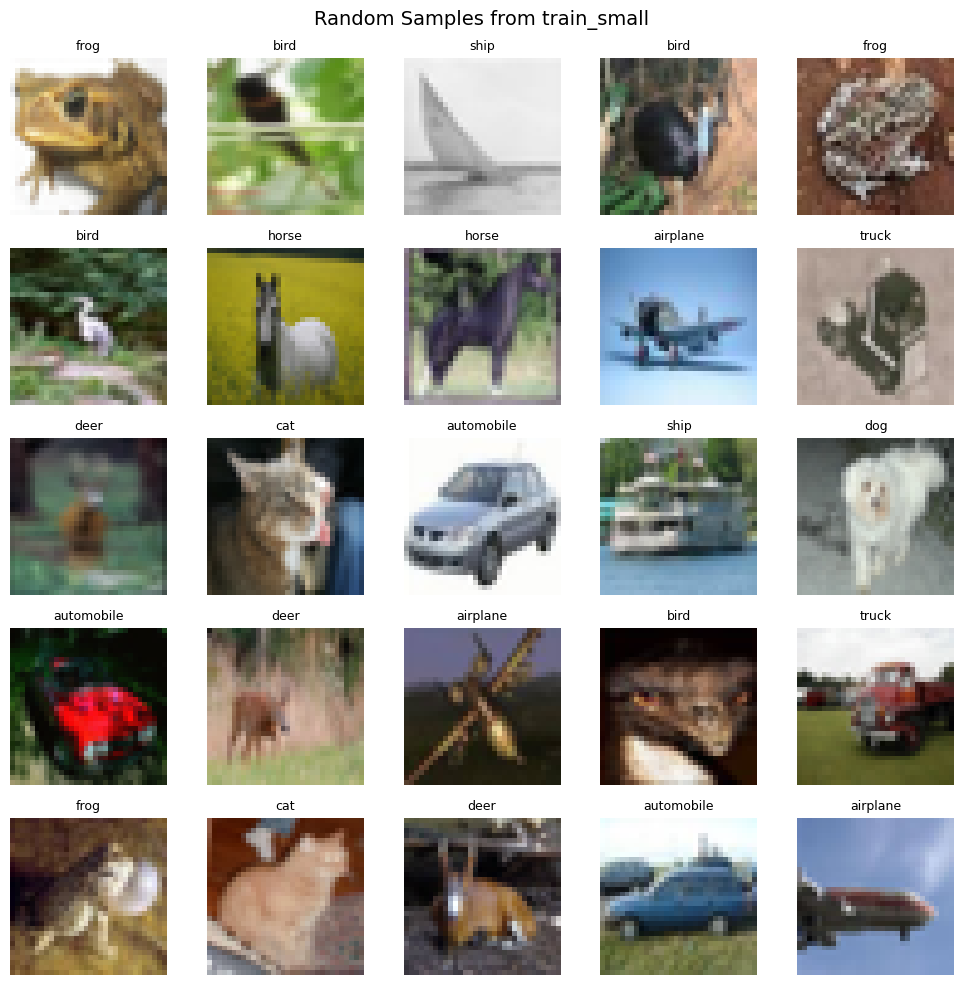

In [6]:
# Display 2 examples from each class
fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for class_id, ax in enumerate(axes.flat):
    indices = np.where(y_small == class_id)[0]
    image_idx = indices[0]

    ax.imshow(train_small[image_idx])
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.suptitle("CIFAR-10: One Example per Class", fontsize=15)
plt.tight_layout()
plt.show()

# Display a larger random sample
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(train_small), size=25, replace=False)

fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(train_small[idx])
    ax.set_title(class_names[y_small[idx]], fontsize=9)
    ax.axis("off")

plt.suptitle("Random Samples from train_small", fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
import cv2

SHIFTED_FILE = DATA_DIR / "cifar10_shifted_local.npz"

if not SHIFTED_FILE.exists():

    rng = np.random.default_rng(2026)

    shifted_test = np.empty_like(clean_test)

    for i, image in enumerate(clean_test):
        img = image.astype(np.float32)

        # 1. Random rotation up to +/-25 degrees
        angle = rng.uniform(-25, 25)
        matrix = cv2.getRotationMatrix2D((15.5, 15.5), angle, 1.0)

        img = cv2.warpAffine(
            img,
            matrix,
            (32, 32),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT_101
        )

        # 2. Brightness and contrast changes
        contrast = rng.uniform(0.7, 1.3)
        brightness = rng.uniform(-30, 30)
        img = img * contrast + brightness

        # 3. Gaussian blur on a random subset
        if rng.random() < 0.5:
            img = cv2.GaussianBlur(img, (3, 3), sigmaX=0.7)

        # 4. Add Gaussian noise
        if rng.random() < 0.5:
            noise = rng.normal(0, 12, img.shape)
            img = img + noise

        # 6. Additional corruption for a local benchmark:
        # randomly swap red and blue channels on some images
        if rng.random() < 0.2:
            img = img[..., [2, 1, 0]]

        shifted_test[i] = np.clip(img, 0, 255).astype(np.uint8)

    np.savez_compressed(
        SHIFTED_FILE,
        shifted_test=shifted_test,
        y_shifted_test=y_clean_test
    )

    print("Local shifted benchmark generated and saved.")

else:
    print("Loading existing shifted benchmark.")

with np.load(SHIFTED_FILE) as data:
    shifted_test = data["shifted_test"]
    y_shifted_test = data["y_shifted_test"]

print("Shifted test shape:", shifted_test.shape)
print("Labels shape:", y_shifted_test.shape)

Loading existing shifted benchmark.
Shifted test shape: (10000, 32, 32, 3)
Labels shape: (10000,)


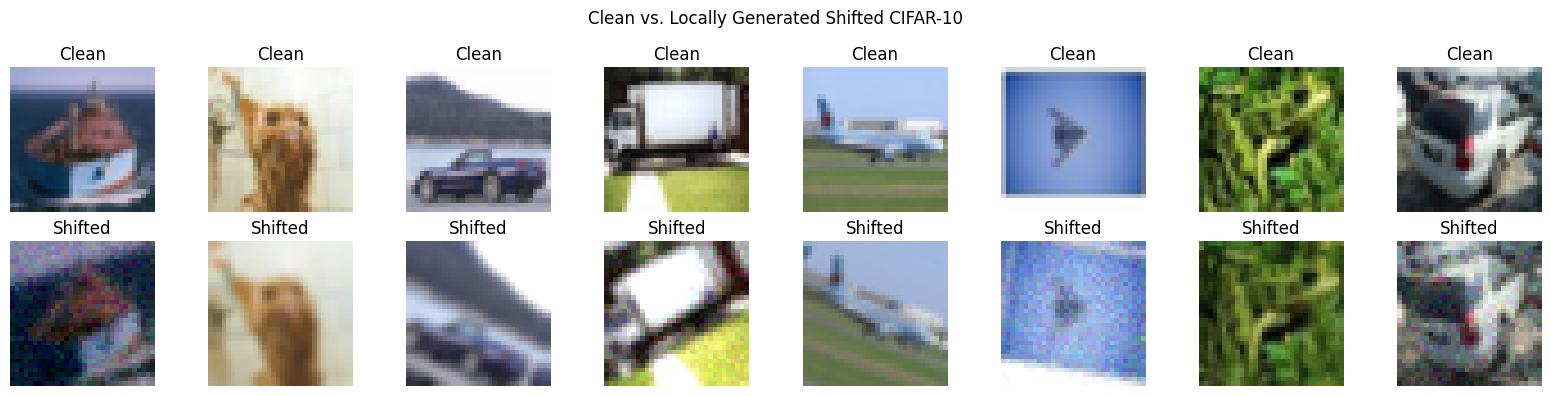

In [8]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(clean_test), size=8, replace=False)

fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for col, idx in enumerate(sample_indices):
    axes[0, col].imshow(clean_test[idx])
    axes[0, col].set_title("Clean")
    axes[0, col].axis("off")

    axes[1, col].imshow(shifted_test[idx])
    axes[1, col].set_title("Shifted")
    axes[1, col].axis("off")

plt.suptitle("Clean vs. Locally Generated Shifted CIFAR-10")
plt.tight_layout()
plt.show()

In [9]:
from tensorflow.keras import layers, Model


def conv_bn_relu(x, filters, kernel_size, strides=1, name=None):
    """Convolution followed by BatchNorm and ReLU."""
    x = layers.Conv2D(
        filters=filters,
        kernel_size=kernel_size,
        strides=strides,
        padding="same",
        use_bias=False,
        name=None if name is None else f"{name}_conv"
    )(x)

    x = layers.BatchNormalization(
        name=None if name is None else f"{name}_bn"
    )(x)

    x = layers.Activation(
        "relu",
        name=None if name is None else f"{name}_relu"
    )(x)

    return x


def inception_module(x, name="inception"):
    """Compact Inception-style module with four parallel branches."""

    # Branch 1: 1x1 convolution
    branch1 = conv_bn_relu(
        x, filters=16, kernel_size=1,
        name=f"{name}_branch1"
    )

    # Branch 2: 1x1 reduction followed by 3x3 convolution
    branch2 = conv_bn_relu(
        x, filters=16, kernel_size=1,
        name=f"{name}_branch2_reduce"
    )
    branch2 = conv_bn_relu(
        branch2, filters=24, kernel_size=3,
        name=f"{name}_branch2"
    )

    # Branch 3: 1x1 reduction followed by 5x5 convolution
    branch3 = conv_bn_relu(
        x, filters=8, kernel_size=1,
        name=f"{name}_branch3_reduce"
    )
    branch3 = conv_bn_relu(
        branch3, filters=12, kernel_size=5,
        name=f"{name}_branch3"
    )

    # Branch 4: pooling followed by a 1x1 projection
    branch4 = layers.MaxPooling2D(
        pool_size=3,
        strides=1,
        padding="same",
        name=f"{name}_branch4_pool"
    )(x)

    branch4 = conv_bn_relu(
        branch4, filters=8, kernel_size=1,
        name=f"{name}_branch4"
    )

    # Combine branch outputs along the channel dimension
    output = layers.Concatenate(
        axis=-1,
        name=f"{name}_concatenate"
    )([branch1, branch2, branch3, branch4])

    return output


def build_cnn():
    inputs = layers.Input(shape=(32, 32, 3), name="image")

    # Initial feature extraction
    x = conv_bn_relu(
        inputs, filters=32, kernel_size=3,
        name="stem"
    )

    # Required Inception-style module
    x = inception_module(x)

    # Downsample and extract higher-level features
    x = conv_bn_relu(
        x, filters=64, kernel_size=3, strides=2,
        name="downsample"
    )

    x = conv_bn_relu(
        x, filters=64, kernel_size=3,
        name="feature_conv"
    )

    # Reduce spatial dimensions without a large Dense layer
    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    # Regularize the classifier
    x = layers.Dropout(0.3, name="classifier_dropout")(x)

    # Output raw logits for 10 classes
    outputs = layers.Dense(10, name="class_logits")(x)

    return Model(inputs=inputs, outputs=outputs, name="CIFAR10_Inception_CNN")


model = build_cnn()

model.summary()

trainable_params = sum(
    np.prod(variable.shape)
    for variable in model.trainable_weights
)

print(f"\nTrainable parameters: {trainable_params:,}")
print("Parameter limit: 1,000,000")


Model: "CIFAR10_Inception_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 32, 32,    │        864 │ image[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 32, 32,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_relu           │ (None, 32, 32,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch2_… │ (None, 32, 32,    │        512 │ stem_relu[0][0]   │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch3_… │ (None, 32, 32, 8) │        256 │ stem_relu[0][0]   │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch2_… │ (None, 32, 32,    │         64 │ inception_branch… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch3_… │ (None, 32, 32, 8) │         32 │ inception_branch… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch2_… │ (None, 32, 32,    │          0 │ inception_branch… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch3_… │ (None, 32, 32, 8) │          0 │ inception_branch… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch4_… │ (None, 32, 32,    │          0 │ stem_relu[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch1_… │ (None, 32, 32,    │        512 │ stem_relu[0][0]   │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch2_… │ (None, 32, 32,    │      3,456 │ inception_branch… │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch3_… │ (None, 32, 32,    │      2,400 │ inception_branch… │
│ (Conv2D)            │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch4_… │ (None, 32, 32, 8) │        256 │ inception_branch… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch1_… │ (None, 32, 32,    │         64 │ inception_branch… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_branch2_… │ (None, 32, 32,    │         96 │ inception_branch… │
│ (BatchNormalizatio… │ 24)               │            │                 

 Total params: 81,306 (317.60 KB)

 Trainable params: 80,818 (315.70 KB)

 Non-trainable params: 488 (1.91 KB)


Trainable parameters: 80,818
Parameter limit: 1,000,000


In [12]:
# Convert pixels to float32 and normalize to [0, 1]
x_train_norm = x_train.astype("float32") / 255.0
x_val_norm = x_val.astype("float32") / 255.0

print("Training range:", x_train_norm.min(), x_train_norm.max())
print("Validation range:", x_val_norm.min(), x_val_norm.max())

print("Training shape:", x_train_norm.shape)
print("Validation shape:", x_val_norm.shape)

Training range: 0.0 1.0
Validation range: 0.0 1.0
Training shape: (400, 32, 32, 3)
Validation shape: (100, 32, 32, 3)


In [13]:
from pathlib import Path
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

CHECKPOINT_DIR = DATA_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_SEEDS = [42, 123, 2026]
baseline_histories = {}
baseline_results = {}

for seed in BASELINE_SEEDS:
    print(f"\n{'=' * 20} Baseline seed: {seed} {'=' * 20}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    model = build_cnn()

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-1),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits=True
        ),
        metrics=["accuracy"]
    )

    checkpoint_path = CHECKPOINT_DIR / f"baseline_seed_{seed}.weights.h5"

    callbacks = [
        ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
            verbose=0
        ),
        # EarlyStopping(
        #     monitor="val_loss",
        #     patience=10,
        #     restore_best_weights=True,
        #     verbose=1
        # ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=1
        )
    ]

    history = model.fit(
        x_train_norm,
        y_train,
        validation_data=(x_val_norm, y_val),
        epochs=60,
        batch_size=32,
        callbacks=callbacks,
        verbose=1
    )

    # Load the best checkpoint explicitly
    model.load_weights(str(checkpoint_path))

    # Evaluate only on training and validation data at this stage
    train_loss, train_acc = model.evaluate(
        x_train_norm, y_train, verbose=0
    )
    val_loss, val_acc = model.evaluate(
        x_val_norm, y_val, verbose=0
    )

    baseline_histories[seed] = history.history
    baseline_results[seed] = {
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "best_epoch": int(np.argmin(history.history["val_loss"]) + 1)
    }

    print(f"Best epoch: {baseline_results[seed]['best_epoch']}")
    print(f"Train accuracy: {train_acc:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Checkpoint: {checkpoint_path}")


==================== Baseline seed: 42 ====================
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 0.1175 - loss: 2.6200 - val_accuracy: 0.1000 - val_loss: 3816.3547 - learning_rate: 0.1000
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.1700 - loss: 2.2054 - val_accuracy: 0.1000 - val_loss: 581.1547 - learning_rate: 0.1000
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.1750 - loss: 2.1135 - val_accuracy: 0.1000 - val_loss: 161.8495 - learning_rate: 0.1000
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2150 - loss: 2.0712 - val_accuracy: 0.1000 - val_loss: 105.3069 - learning_rate: 0.1000
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.1950 - loss: 2.0481 - val_accuracy: 0.1000 - val_loss: 32.1246 - learning_rate: 0.1000
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.1950 - loss: 2.0419 - val_accuracy: 0.1000 - val_loss: 22.8783 - learning_rate: 0.1000
Epoch 7/60
13/13 ━━━

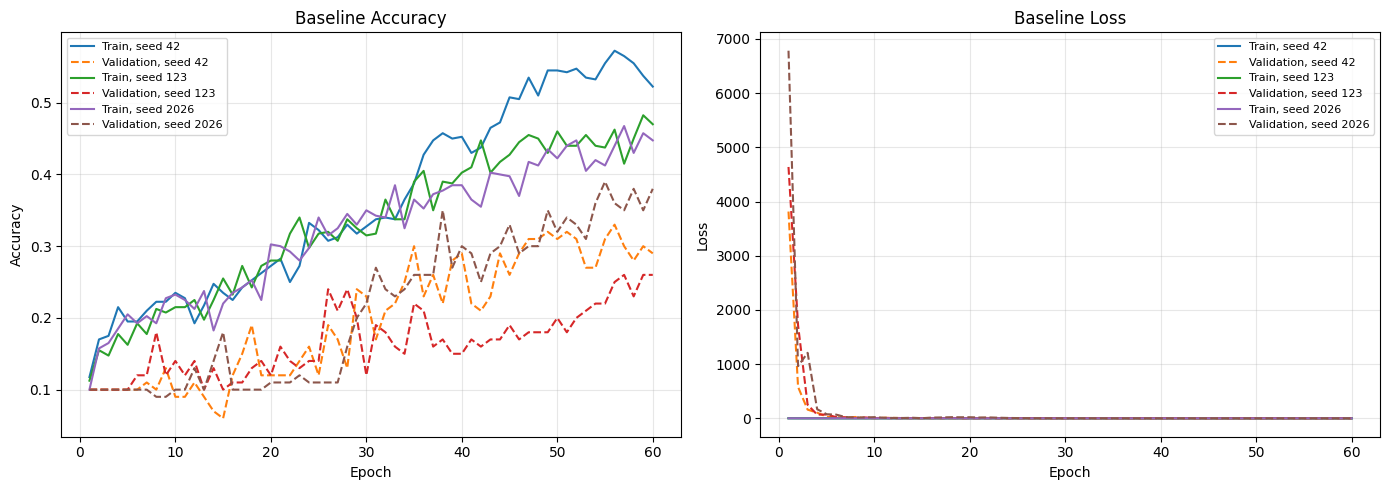

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for seed, history in baseline_histories.items():
    epochs = range(1, len(history["loss"]) + 1)

    axes[0].plot(
        epochs, history["accuracy"],
        label=f"Train, seed {seed}"
    )
    axes[0].plot(
        epochs, history["val_accuracy"],
        linestyle="--",
        label=f"Validation, seed {seed}"
    )

    axes[1].plot(
        epochs, history["loss"],
        label=f"Train, seed {seed}"
    )
    axes[1].plot(
        epochs, history["val_loss"],
        linestyle="--",
        label=f"Validation, seed {seed}"
    )

axes[0].set_title("Baseline Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Baseline Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Geometric augmentation pipeline
geometric_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal",
        seed=101
    ),
    tf.keras.layers.RandomRotation(
        factor=25 / 360,
        fill_mode="reflect",
        seed=102
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect",
        seed=103
    )
], name="geometric_augmentation")

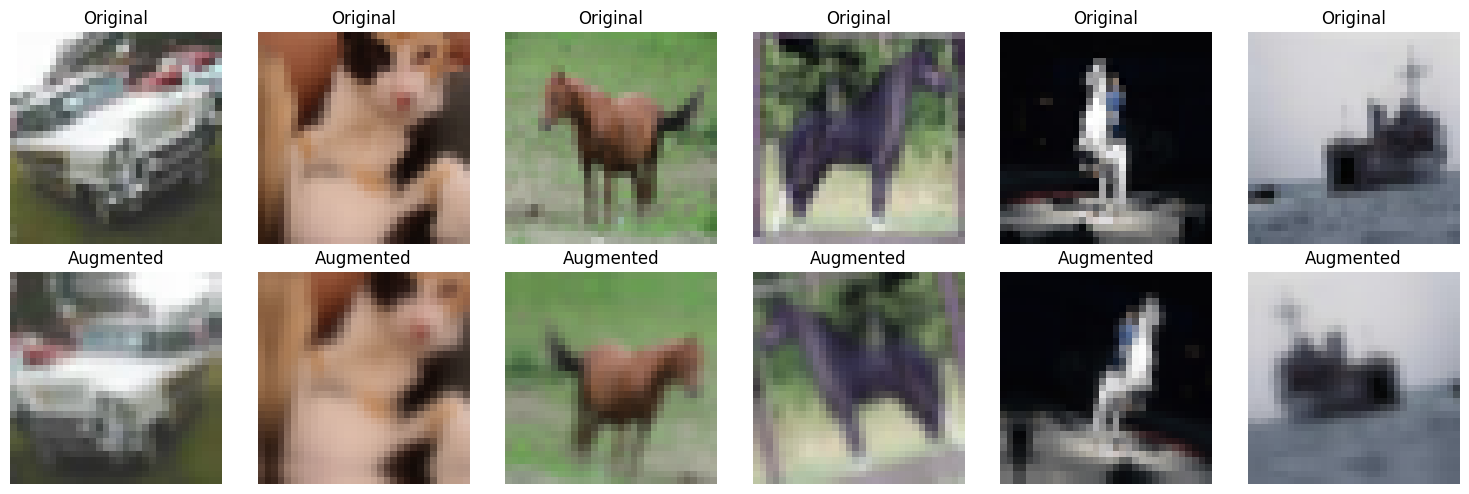

In [17]:
# Keep original arrays unchanged; use normalized float32 copies.
x_train_norm = x_train.astype("float32") / 255.0
x_val_norm = x_val.astype("float32") / 255.0

# Select a few images from the training set.
sample_images = x_train_norm[:6]

# Generate augmented versions.
augmented_images = geometric_augmentation(
    sample_images,
    training=True
).numpy()

# Plot original and augmented images side by side.
fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for i in range(6):
    axes[0, i].imshow(sample_images[i])
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        augmented_images[i].clip(0, 1)
    )
    axes[1, i].set_title("Augmented")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [18]:
photometric_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 1),
        seed=201
    ),
    tf.keras.layers.RandomContrast(
        factor=0.15,
        seed=202
    )
], name="photometric_augmentation")

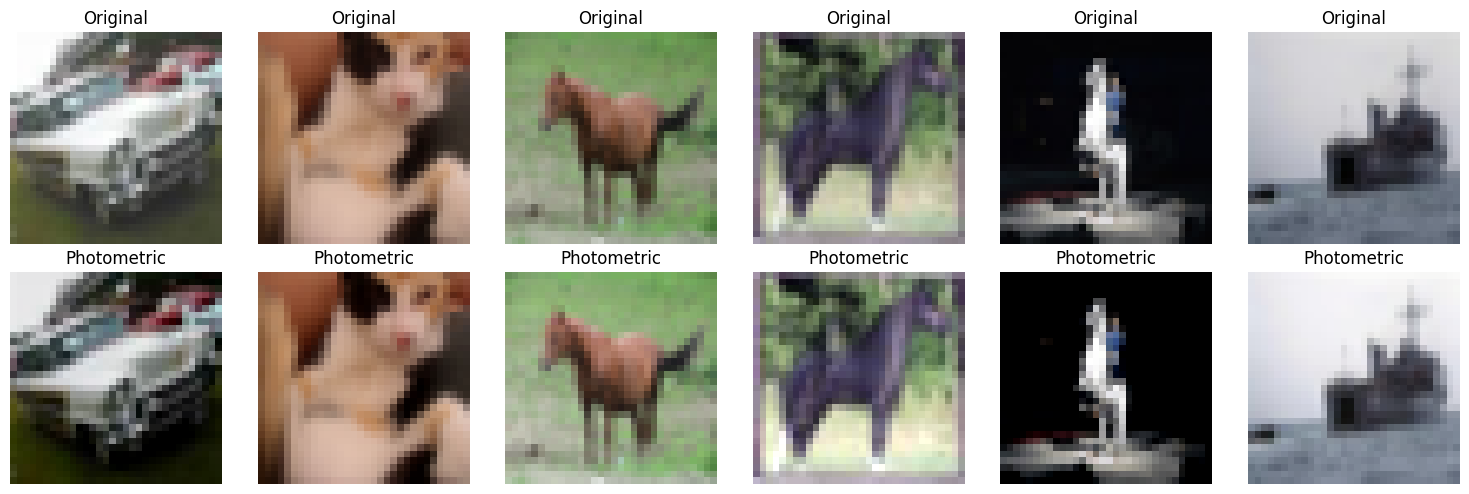

In [19]:
photometric_images = photometric_augmentation(
    sample_images,
    training=True
).numpy()

fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for i in range(6):
    axes[0, i].imshow(sample_images[i])
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        photometric_images[i].clip(0, 1)
    )
    axes[1, i].set_title("Photometric")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [20]:
combined_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal",
        seed=301
    ),
    tf.keras.layers.RandomRotation(
        factor=25 / 360,
        fill_mode="reflect",
        seed=302
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1,
        fill_mode="reflect",
        seed=303
    ),
    tf.keras.layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 1),
        seed=304
    ),
    tf.keras.layers.RandomContrast(
        factor=0.15,
        seed=305
    )
], name="combined_augmentation")

In [21]:
def random_cutout(images, mask_size=8):
    """
    images: batch of float32 images with shape (B, H, W, C)
            and pixel values in [0, 1].
    mask_size: side length of the square mask.
    """
    images = tf.convert_to_tensor(images, dtype=tf.float32)

    batch_size = tf.shape(images)[0]
    height = tf.shape(images)[1]
    width = tf.shape(images)[2]

    top = tf.random.uniform(
        (batch_size,), 0, height - mask_size + 1,
        dtype=tf.int32
    )
    left = tf.random.uniform(
        (batch_size,), 0, width - mask_size + 1,
        dtype=tf.int32
    )

    rows = tf.range(height)[None, :, None]
    cols = tf.range(width)[None, None, :]

    mask_rows = (rows >= top[:, None, None]) & (
        rows < (top + mask_size)[:, None, None]
    )
    mask_cols = (cols >= left[:, None, None]) & (
        cols < (left + mask_size)[:, None, None]
    )

    masked_region = mask_rows & mask_cols
    keep_mask = tf.cast(~masked_region[..., None], images.dtype)

    return images * keep_mask

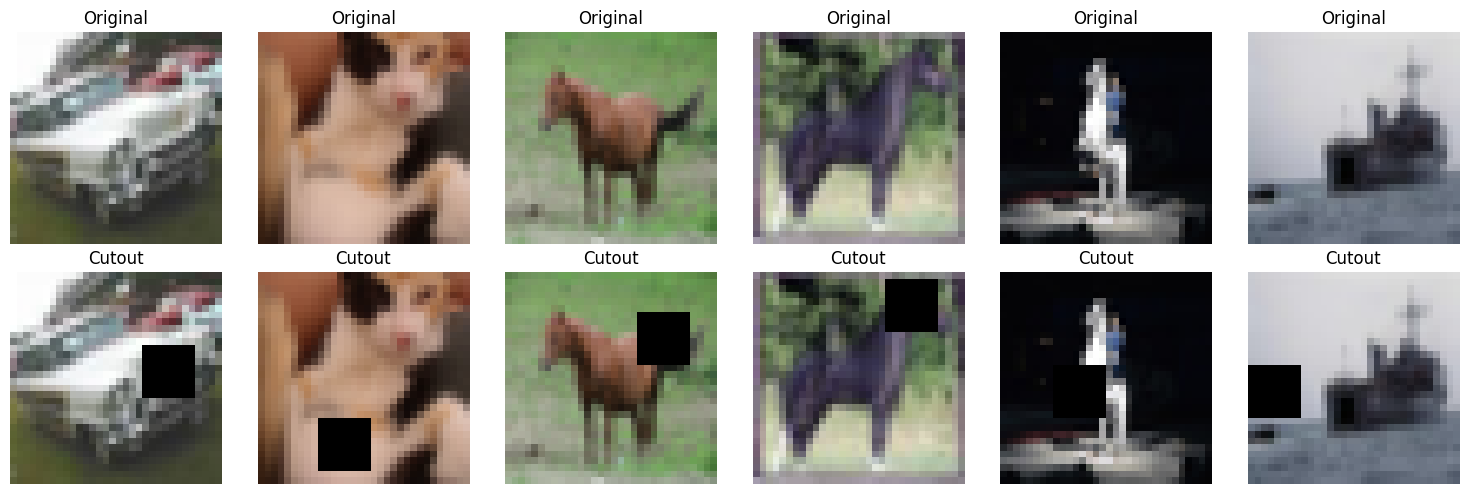

In [22]:
cutout_images = random_cutout(sample_images, mask_size=8).numpy()

fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for i in range(6):
    axes[0, i].imshow(sample_images[i])
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(cutout_images[i].clip(0, 1))
    axes[1, i].set_title("Cutout")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [23]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

def make_dataset(
    images,
    labels,
    augmentation="none",
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=42
):
    # Normalize pixels to [0, 1] and use integer labels.
    images = images.astype("float32") / 255.0
    labels = labels.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((images, labels))

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(images),
            seed=seed,
            reshuffle_each_iteration=True
        )

    # Batch before augmentation because Cutout operates on batches.
    ds = ds.batch(batch_size)

    def apply_augmentation(batch_images, batch_labels):
        if augmentation == "geometric":
            batch_images = geometric_augmentation(
                batch_images, training=True
            )

        elif augmentation == "photometric":
            batch_images = photometric_augmentation(
                batch_images, training=True
            )

        elif augmentation in ("combined", "combined_cutout"):
            batch_images = combined_augmentation(
                batch_images, training=True
            )

            if augmentation == "combined_cutout":
                batch_images = random_cutout(
                    batch_images, mask_size=8
                )

        elif augmentation != "none":
            raise ValueError(
                f"Unknown augmentation: {augmentation}"
            )

        batch_images = tf.clip_by_value(batch_images, 0.0, 1.0)
        return batch_images, batch_labels

    if augmentation != "none":
        ds = ds.map(
            apply_augmentation,
            num_parallel_calls=AUTOTUNE
        )

    return ds.prefetch(AUTOTUNE)

In [24]:
train_ds = make_dataset(
    x_train,
    y_train,
    augmentation="geometric",
    shuffle=True,
    seed=42
)

# Validation is normalized but never augmented.
val_ds = make_dataset(
    x_val,
    y_val,
    augmentation="none",
    shuffle=False
)

for images, labels in train_ds.take(1):
    print("Training batch shape:", images.shape)
    print("Training labels shape:", labels.shape)
    print("Training pixel range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))

for images, labels in val_ds.take(1):
    print("\nValidation batch shape:", images.shape)
    print("Validation labels shape:", labels.shape)
    print("Validation pixel range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))

Training batch shape: (32, 32, 32, 3)
Training labels shape: (32,)
Training pixel range: 0.00012883827730547637 1.0

Validation batch shape: (32, 32, 32, 3)
Validation labels shape: (32,)
Validation pixel range: 0.0 1.0


In [25]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.3875 - loss: 1.6261 - val_accuracy: 0.3100 - val_loss: 1.8323 - learning_rate: 0.0031
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.3675 - loss: 1.6349 - val_accuracy: 0.2800 - val_loss: 1.9595 - learning_rate: 0.0031
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.3450 - loss: 1.6619 - val_accuracy: 0.3500 - val_loss: 1.7293 - learning_rate: 0.0031
Epoch 4/60
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3847 - loss: 1.5922
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0015625000232830644.
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3525 - loss: 1.6867 - val_accuracy: 0.3700 - val_loss: 1.7421 - learning_rate: 0.0031
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.3600 - loss: 1.6157 - val_accuracy: 0.3600 - val_loss: 1.7560 - learning_rate: 0.0016
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3750 - loss: 1.6727 - val_accu

In [27]:
from pathlib import Path
import numpy as np
import tensorflow as tf

EXPERIMENT_SEEDS = [42, 123, 2026]
AUGMENTATION_VARIANTS = [
    "none",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout"
]

EXPERIMENT_LR = 0.1
EXPERIMENT_EPOCHS = 60

AUG_CHECKPOINT_DIR = DATA_DIR / "augmentation_checkpoints"
AUG_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

augmentation_histories = {}
augmentation_results = {}

for variant in AUGMENTATION_VARIANTS:
    for seed in EXPERIMENT_SEEDS:
        print(f"\n{'=' * 60}")
        print(f"Variant: {variant} | Seed: {seed}")
        print(f"{'=' * 60}")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        train_ds = make_dataset(
            x_train,
            y_train,
            augmentation=variant,
            shuffle=True,
            seed=seed
        )

        val_ds = make_dataset(
            x_val,
            y_val,
            augmentation="none",
            shuffle=False
        )

        model = build_cnn()
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=EXPERIMENT_LR
            ),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(
                from_logits=True
            ),
            metrics=["accuracy"]
        )

        checkpoint_path = (
            AUG_CHECKPOINT_DIR /
            f"{variant}_seed_{seed}.weights.h5"
        )

        callbacks = [
            tf.keras.callbacks.ModelCheckpoint(
                filepath=str(checkpoint_path),
                monitor="val_loss",
                save_best_only=True,
                save_weights_only=True,
                mode="min",
                verbose=0
            ),

            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=4,
                min_lr=1e-6,
                mode="min",
                verbose=1
            )
        ]

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EXPERIMENT_EPOCHS,
            callbacks=callbacks,
            verbose=1
        )

        # Load the checkpoint with the lowest validation loss.
        model.load_weights(str(checkpoint_path))

        best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

        # Store histories and validation results only.
        key = (variant, seed)
        augmentation_histories[key] = history.history
        augmentation_results[key] = {
            "best_epoch": best_epoch,
            "best_val_loss": float(
                min(history.history["val_loss"])
            ),
            "best_val_accuracy": float(
                max(
                    history.history["val_accuracy"][
                        :best_epoch
                    ]
                )
            ),
            "checkpoint": str(checkpoint_path)
        }

        print(f"Best epoch: {best_epoch}")
        print(
            "Best validation loss:",
            round(augmentation_results[key]["best_val_loss"], 4)
        )
        print(
            "Best validation accuracy:",
            round(augmentation_results[key]["best_val_accuracy"], 4)
        )


Variant: none | Seed: 42
Epoch 1/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.1050 - loss: 2.6720 - val_accuracy: 0.1000 - val_loss: 5543.9043 - learning_rate: 0.1000
Epoch 2/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1100 - loss: 2.3308 - val_accuracy: 0.1000 - val_loss: 376.8739 - learning_rate: 0.1000
Epoch 3/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1375 - loss: 2.2438 - val_accuracy: 0.1000 - val_loss: 112.5047 - learning_rate: 0.1000
Epoch 4/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1475 - loss: 2.2204 - val_accuracy: 0.1000 - val_loss: 74.3325 - learning_rate: 0.1000
Epoch 5/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1600 - loss: 2.2119 - val_accuracy: 0.1000 - val_loss: 42.5234 - learning_rate: 0.1000
Epoch 6/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1350 - loss: 2.2076 - val_accuracy: 0.1000 - val_loss: 26.9639 - learning_rate: 0.1000
Epoch 7/60
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accur

In [28]:
import numpy as np

print("=" * 85)
print("AUGMENTATION EXPERIMENT RESULTS")
print("=" * 85)

for variant in AUGMENTATION_VARIANTS:
    print(f"\nVariant: {variant}")
    print("-" * 65)
    print(f"{'Seed':<10}{'Best Epoch':<15}{'Val Loss':<15}{'Val Accuracy':<15}")

    val_losses = []
    val_accuracies = []

    for seed in EXPERIMENT_SEEDS:
        result = augmentation_results[(variant, seed)]
        history = augmentation_histories[(variant, seed)]

        best_epoch = result["best_epoch"]

        # Use metrics from the same epoch selected by minimum val_loss.
        val_loss = history["val_loss"][best_epoch - 1]
        val_accuracy = history["val_accuracy"][best_epoch - 1]

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(
            f"{seed:<10}"
            f"{best_epoch:<15}"
            f"{val_loss:<15.4f}"
            f"{val_accuracy:<15.4f}"
        )

    print("-" * 65)
    print(
        f"{'Mean':<25}"
        f"{np.mean(val_losses):<15.4f}"
        f"{np.mean(val_accuracies):<15.4f}"
    )
    print(
        f"{'Std Dev':<25}"
        f"{np.std(val_losses):<15.4f}"
        f"{np.std(val_accuracies):<15.4f}"
    )

AUGMENTATION EXPERIMENT RESULTS

Variant: none
-----------------------------------------------------------------
Seed      Best Epoch     Val Loss       Val Accuracy   
42        60             1.8561         0.3200         
123       56             1.6338         0.3100         
2026      57             1.7714         0.2600         
-----------------------------------------------------------------
Mean                     1.7537         0.2967         
Std Dev                  0.0916         0.0262         

Variant: geometric
-----------------------------------------------------------------
Seed      Best Epoch     Val Loss       Val Accuracy   
42        45             1.9033         0.2100         
123       42             1.7872         0.2900         
2026      45             1.7618         0.2600         
-----------------------------------------------------------------
Mean                     1.8174         0.2533         
Std Dev                  0.0616         0.0330       

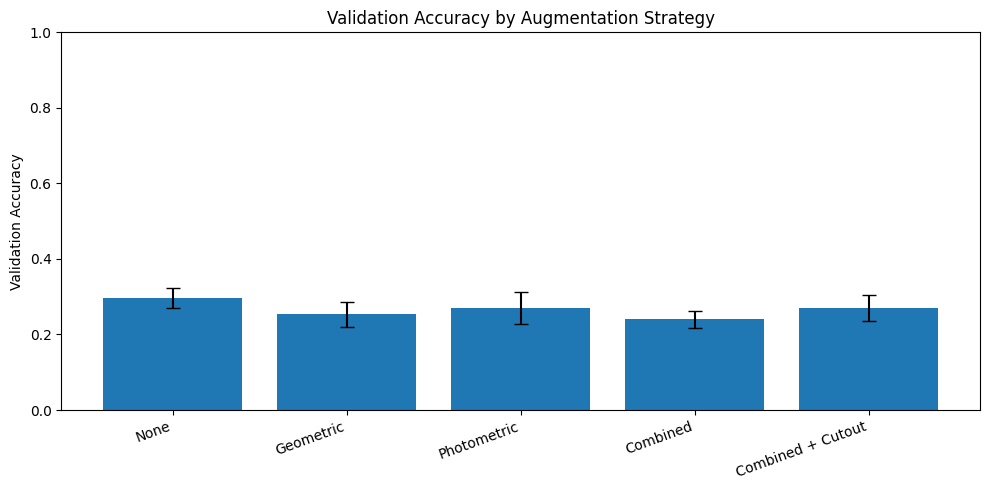

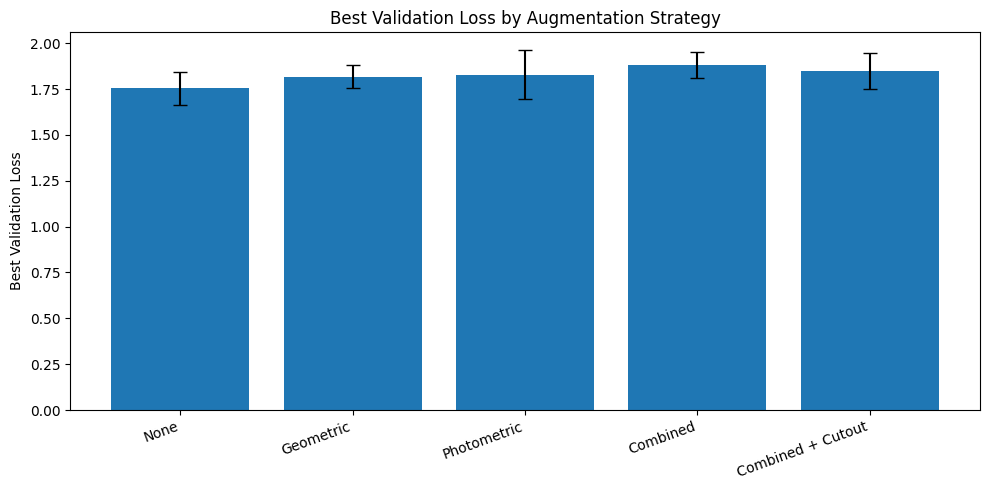

In [29]:
import numpy as np
import matplotlib.pyplot as plt

variants = AUGMENTATION_VARIANTS

mean_accuracies = []
std_accuracies = []
mean_losses = []
std_losses = []

for variant in variants:
    accuracies = []
    losses = []

    for seed in EXPERIMENT_SEEDS:
        history = augmentation_histories[(variant, seed)]
        best_epoch = int(np.argmin(history["val_loss"]))

        # Metrics from the same epoch selected by minimum validation loss.
        accuracies.append(history["val_accuracy"][best_epoch])
        losses.append(history["val_loss"][best_epoch])

    mean_accuracies.append(np.mean(accuracies))
    std_accuracies.append(np.std(accuracies))
    mean_losses.append(np.mean(losses))
    std_losses.append(np.std(losses))

labels = [
    "None",
    "Geometric",
    "Photometric",
    "Combined",
    "Combined + Cutout"
]

# Mean validation accuracy
plt.figure(figsize=(10, 5))
plt.bar(
    labels,
    mean_accuracies,
    yerr=std_accuracies,
    capsize=5
)
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Augmentation Strategy")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Mean best validation loss
plt.figure(figsize=(10, 5))
plt.bar(
    labels,
    mean_losses,
    yerr=std_losses,
    capsize=5
)
plt.ylabel("Best Validation Loss")
plt.title("Best Validation Loss by Augmentation Strategy")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [30]:
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

variant_summaries = []

for variant in AUGMENTATION_VARIANTS:
    accuracies = []
    losses = []

    for seed in EXPERIMENT_SEEDS:
        history = augmentation_histories[(variant, seed)]
        best_epoch = int(np.argmin(history["val_loss"]))

        accuracies.append(history["val_accuracy"][best_epoch])
        losses.append(history["val_loss"][best_epoch])

    variant_summaries.append({
        "variant": variant,
        "mean_val_accuracy": np.mean(accuracies),
        "mean_val_loss": np.mean(losses)
    })

variant_summary_df = pd.DataFrame(variant_summaries)

# Highest mean validation accuracy, then lowest mean validation loss.
variant_summary_df = variant_summary_df.sort_values(
    ["mean_val_accuracy", "mean_val_loss"],
    ascending=[False, True]
).reset_index(drop=True)

print(variant_summary_df.to_string(index=False))

FINAL_VARIANT = variant_summary_df.iloc[0]["variant"]

# Select the seed with the lowest best validation loss
# within the selected variant.
FINAL_SEED = min(
    EXPERIMENT_SEEDS,
    key=lambda seed: augmentation_results[
        (FINAL_VARIANT, seed)
    ]["best_val_loss"]
)

FINAL_CHECKPOINT = (
    AUG_CHECKPOINT_DIR /
    f"{FINAL_VARIANT}_seed_{FINAL_SEED}.weights.h5"
)

print("\nSelected variant:", FINAL_VARIANT)
print("Selected seed:", FINAL_SEED)
print("Checkpoint:", FINAL_CHECKPOINT)

        variant  mean_val_accuracy  mean_val_loss
           none           0.296667       1.753733
    photometric           0.270000       1.829381
combined_cutout           0.270000       1.849766
      geometric           0.253333       1.817430
       combined           0.240000       1.880051

Selected variant: none
Selected seed: 123
Checkpoint: /content/drive/MyDrive/DL_Assignment/data/augmentation_checkpoints/none_seed_123.weights.h5


In [31]:
shifted_data = np.load(SHIFTED_FILE)

print("Saved arrays:", shifted_data.files)

image_keys = [
    key for key in shifted_data.files
    if shifted_data[key].ndim == 4
    and shifted_data[key].shape[1:] == (32, 32, 3)
]

label_keys = [
    key for key in shifted_data.files
    if shifted_data[key].ndim == 1
    and len(shifted_data[key]) == len(clean_test)
]

# Prefer keys explicitly referring to shifted data.
shifted_image_key = next(
    (k for k in image_keys if "shift" in k.lower()),
    image_keys[0] if len(image_keys) == 1 else None
)

shifted_label_key = next(
    (k for k in label_keys if "label" in k.lower() or k.lower().startswith("y")),
    label_keys[0] if len(label_keys) == 1 else None
)

if shifted_image_key is None or shifted_label_key is None:
    raise ValueError(
        "Could not uniquely identify shifted images and labels. "
        "Check the printed array keys and assign them manually."
    )

x_shifted_test = shifted_data[shifted_image_key]
y_shifted_test = shifted_data[shifted_label_key].astype("int32").reshape(-1)

y_clean = np.asarray(y_clean_test).astype("int32").reshape(-1)

assert len(x_shifted_test) == len(y_shifted_test) == len(clean_test)
assert len(y_clean) == len(clean_test)

print("Shifted images:", x_shifted_test.shape)
print("Shifted labels:", y_shifted_test.shape)
print("Clean test:", clean_test.shape)
print("Labels match:", np.array_equal(y_clean, y_shifted_test))

Saved arrays: ['shifted_test', 'y_shifted_test']
Shifted images: (10000, 32, 32, 3)
Shifted labels: (10000,)
Clean test: (10000, 32, 32, 3)
Labels match: True


In [32]:
from sklearn.metrics import accuracy_score

x_clean_norm = clean_test.astype("float32") / 255.0
x_shifted_norm = x_shifted_test.astype("float32") / 255.0

test_results = []

for variant in AUGMENTATION_VARIANTS:
    for seed in EXPERIMENT_SEEDS:
        checkpoint = (
            AUG_CHECKPOINT_DIR /
            f"{variant}_seed_{seed}.weights.h5"
        )

        model = build_cnn()
        model.load_weights(str(checkpoint))

        clean_logits = model.predict(
            x_clean_norm, batch_size=128, verbose=0
        )
        shifted_logits = model.predict(
            x_shifted_norm, batch_size=128, verbose=0
        )

        clean_pred = np.argmax(clean_logits, axis=1)
        shifted_pred = np.argmax(shifted_logits, axis=1)

        test_results.append({
            "variant": variant,
            "seed": seed,
            "clean_accuracy": accuracy_score(y_clean, clean_pred),
            "shifted_accuracy": accuracy_score(
                y_shifted_test, shifted_pred
            )
        })

        del model

test_results_df = pd.DataFrame(test_results)

print("Test metrics by variant and seed:")
print(test_results_df.to_string(index=False))

print("\nMean ± standard deviation across seeds:")
test_summary = test_results_df.groupby("variant").agg(
    clean_mean=("clean_accuracy", "mean"),
    clean_std=("clean_accuracy", "std"),
    shifted_mean=("shifted_accuracy", "mean"),
    shifted_std=("shifted_accuracy", "std")
)

for variant, row in test_summary.iterrows():
    print(
        f"{variant:20s} "
        f"Clean: {row['clean_mean']:.4f} ± {row['clean_std']:.4f} | "
        f"Shifted: {row['shifted_mean']:.4f} ± {row['shifted_std']:.4f}"
    )

Test metrics by variant and seed:
        variant  seed  clean_accuracy  shifted_accuracy
           none    42          0.2772            0.2003
           none   123          0.3015            0.2271
           none  2026          0.2927            0.2239
      geometric    42          0.2607            0.2118
      geometric   123          0.2838            0.2220
      geometric  2026          0.2815            0.2312
    photometric    42          0.2366            0.1985
    photometric   123          0.3065            0.2423
    photometric  2026          0.2779            0.2238
       combined    42          0.2462            0.1929
       combined   123          0.2892            0.2443
       combined  2026          0.2809            0.2291
combined_cutout    42          0.2260            0.1844
combined_cutout   123          0.2753            0.2188
combined_cutout  2026          0.2839            0.2423

Mean ± standard deviation across seeds:
combined             Clean: 0

Clean test classification report:
              precision    recall  f1-score   support

    airplane     0.3846    0.3450    0.3637      1000
  automobile     0.4547    0.3760    0.4116      1000
        bird     0.1959    0.0480    0.0771      1000
         cat     0.2181    0.2600    0.2372      1000
        deer     0.3344    0.3150    0.3244      1000
         dog     0.1835    0.3140    0.2316      1000
        frog     0.3086    0.4250    0.3576      1000
       horse     0.3431    0.1760    0.2327      1000
        ship     0.3686    0.4080    0.3873      1000
       truck     0.2927    0.3480    0.3180      1000

    accuracy                         0.3015     10000
   macro avg     0.3084    0.3015    0.2941     10000
weighted avg     0.3084    0.3015    0.2941     10000



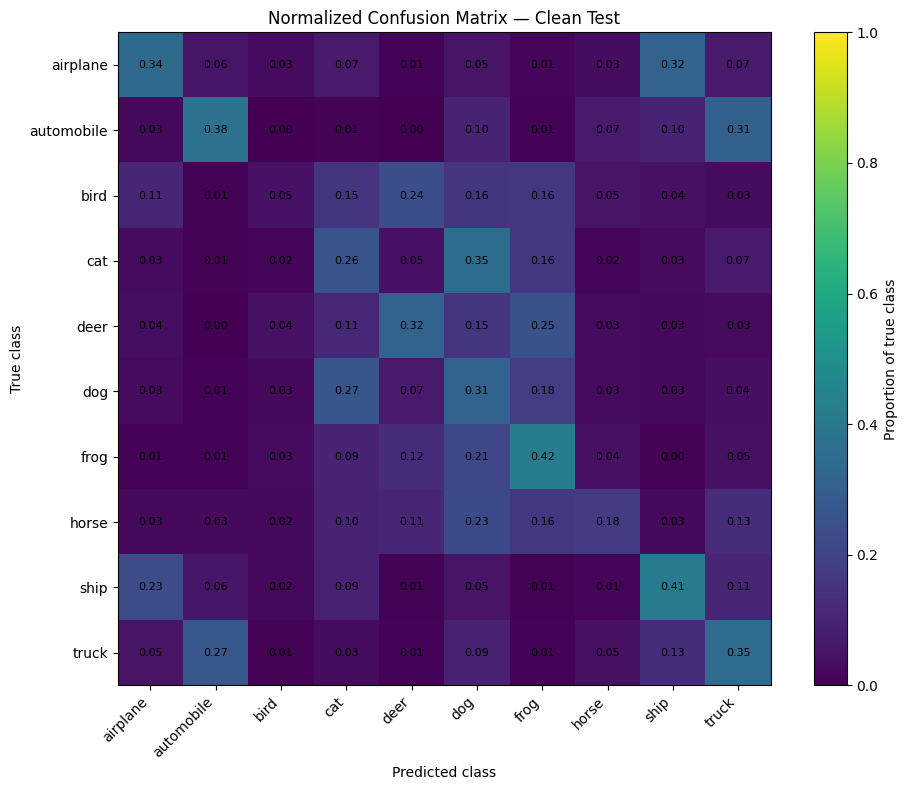

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

final_model = build_cnn()
final_model.load_weights(str(FINAL_CHECKPOINT))

clean_logits = final_model.predict(
    x_clean_norm, batch_size=128, verbose=0
)
clean_pred = np.argmax(clean_logits, axis=1)

print("Clean test classification report:")
print(classification_report(
    y_clean,
    clean_pred,
    labels=np.arange(10),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_clean, clean_pred, labels=np.arange(10))
row_totals = cm.sum(axis=1, keepdims=True)
cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

plt.figure(figsize=(10, 8))
plt.imshow(cm_normalized, interpolation="nearest", vmin=0, vmax=1)
plt.title("Normalized Confusion Matrix — Clean Test")
plt.colorbar(label="Proportion of true class")
plt.xticks(np.arange(10), class_names, rotation=45, ha="right")
plt.yticks(np.arange(10), class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, f"{cm_normalized[i, j]:.2f}",
            ha="center", va="center",
            color="white" if cm_normalized[i, j] > 0.5 else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

Misclassified clean-test images: 6985 / 10000


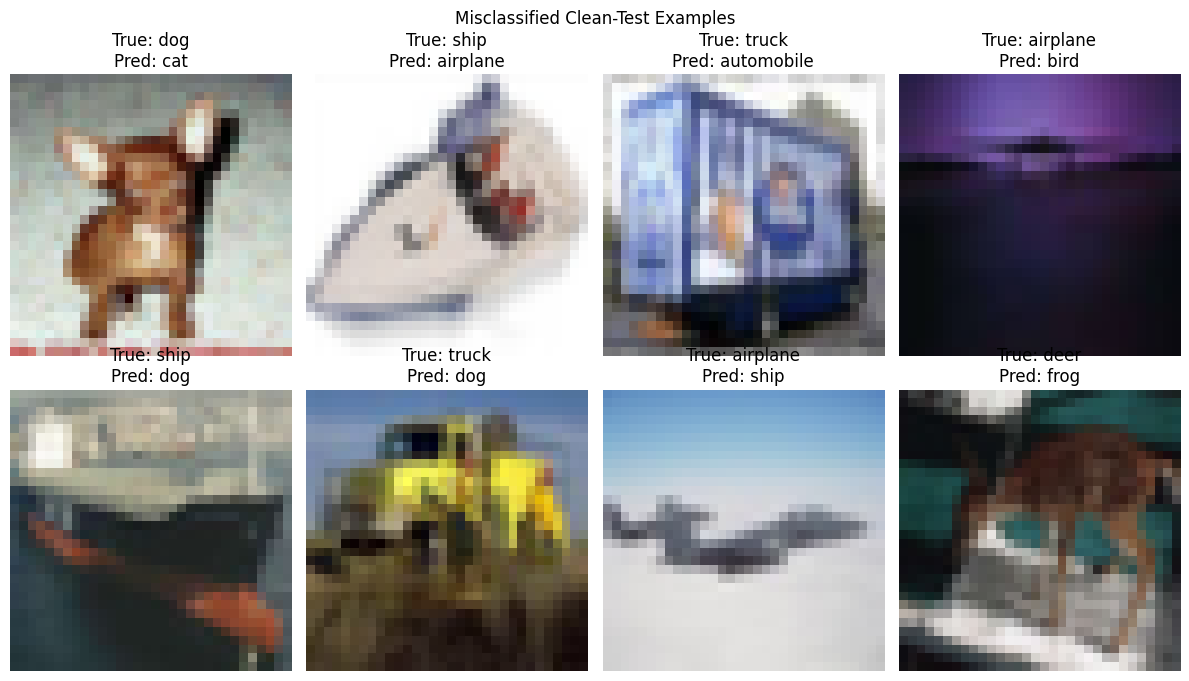

In [34]:
wrong_indices = np.where(clean_pred != y_clean)[0]
print(f"Misclassified clean-test images: {len(wrong_indices)} / {len(y_clean)}")

if len(wrong_indices) == 0:
    print("No misclassified images found.")
else:
    # Choose eight examples reproducibly.
    rng = np.random.default_rng(42)
    selected = rng.choice(
        wrong_indices,
        size=min(8, len(wrong_indices)),
        replace=False
    )

    fig, axes = plt.subplots(2, 4, figsize=(12, 7))

    for ax, idx in zip(axes.flat, selected):
        ax.imshow(clean_test[idx])
        ax.set_title(
            f"True: {class_names[y_clean[idx]]}\n"
            f"Pred: {class_names[clean_pred[idx]]}"
        )
        ax.axis("off")

    for ax in axes.flat[len(selected):]:
        ax.axis("off")

    plt.suptitle("Misclassified Clean-Test Examples")
    plt.tight_layout()
    plt.show()

In [35]:
RESULTS_DIR = DATA_DIR / "final_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

test_results_df.to_csv(
    RESULTS_DIR / "augmentation_test_results.csv",
    index=False
)

test_summary.to_csv(
    RESULTS_DIR / "augmentation_test_summary.csv"
)

pd.DataFrame(classification_report(
    y_clean,
    clean_pred,
    labels=np.arange(10),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)).transpose().to_csv(
    RESULTS_DIR / "clean_test_classification_report.csv"
)

np.save(
    RESULTS_DIR / "clean_test_normalized_confusion_matrix.npy",
    cm_normalized
)

print("Results saved to:", RESULTS_DIR)

Results saved to: /content/drive/MyDrive/DL_Assignment/data/final_results
